# Task 1: Exploratory data analysis

Merged from three earlier pieces of work:

- `01_eda_overview_people_digits.ipynb` and `02_eda_sessions_and_limitations.ipynb` (Python)
- `Step_1_Data_Exploration.Rmd` by Lehlonono Nkejane (R), translated to Python here.
  The interpretation text from that file is kept in its author's words, in the cells
  marked *(L. Nkejane)*.

Cells marked **Review note** point out where the evidence in this notebook disagrees with,
or adds to, the text. The group should resolve these before writing the report.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

from data_utils import load_handwriting, select
from eda_plots import show_grid, image_features

images, meta = load_handwriting()            # pixels scaled to [0, 1]
X = images.reshape(len(images), -1)           # flattened: 25000 x 784
features = pd.concat([meta, pd.DataFrame(image_features(images))], axis=1)


def find(person, digit, session, replicate):
    """Row number of one specific image."""
    return np.where((meta.person_id == person) & (meta.digit == digit) &
                    (meta.session == session) & (meta.replicate == replicate))[0][0]


def image_panel(rows, row_labels=None, col_labels=None, cell=0.55, title=None):
    """Plot a grid of images; `rows` is a list of lists of row numbers."""
    n_rows, n_cols = len(rows), len(rows[0])
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(cell * n_cols, cell * n_rows + 0.4),
                             squeeze=False)
    for r in range(n_rows):
        for c in range(n_cols):
            ax = axes[r, c]
            ax.imshow(images[rows[r][c]], cmap="gray_r", vmin=0, vmax=1)
            ax.set_xticks([]); ax.set_yticks([])
            if r == 0 and col_labels is not None and col_labels[c]:
                ax.set_title(col_labels[c], fontsize=7)
            if c == 0 and row_labels is not None:
                ax.set_ylabel(row_labels[r], fontsize=7)
    if title:
        fig.suptitle(title, fontsize=10)
    fig.tight_layout(pad=0.2)
    return fig

## 1. Structure and balance

In [2]:
cell_counts = meta.groupby(["person_id", "digit", "session"]).size()

checks = pd.DataFrame({
    "Check": ["Images", "Image size", "Pixel range (raw)", "Missing values",
              "Images per person x digit x session", "Blank pixels (%)",
              "Writers / digits / sessions"],
    "Value": [len(images), "28 x 28", "0 to 255", int(meta.isna().sum().sum()),
              ", ".join(map(str, cell_counts.unique())), round(100 * (X == 0).mean(), 1),
              f"{meta.person_id.nunique()} / {meta.digit.nunique()} / {meta.session.nunique()}"],
})
checks

,Check,Value
0,Images,25000
1,Image size,28 x 28
2,Pixel range (raw),0 to 255
3,Missing values,0
4,Images per person x digit x session,50
5,Blank pixels (%),84.7
6,Writers / digits / sessions,20 / 5 / 5


*(L. Nkejane)* The table summarises the structure of the dataset. It contains 25,000 images of
28 × 28 pixels, which matches the stated design of 20 people, 5 digits, 5 sessions and 50
replicates per cell. Pixel values range from 0 to 255 with no missing values, so no cleaning or
imputation is required, although intensities should be rescaled to the unit interval before
training a neural network. Every person × digit × session cell contains exactly 50 images, so the
classes are perfectly balanced and no digit, person or session is over-represented. Approximately
84.7% of pixels are blank background, which reflects that each digit is a thin stroke on an empty
canvas. Most raw pixel values therefore carry no information about the digit.

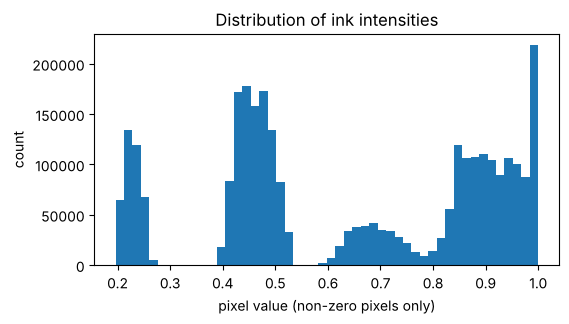

In [3]:
plt.figure(figsize=(6, 3))
plt.hist(X[X > 0], bins=50)
plt.xlabel("pixel value (non-zero pixels only)")
plt.ylabel("count")
plt.title("Distribution of ink intensities")
plt.show()

## 2. Examples across people and digits

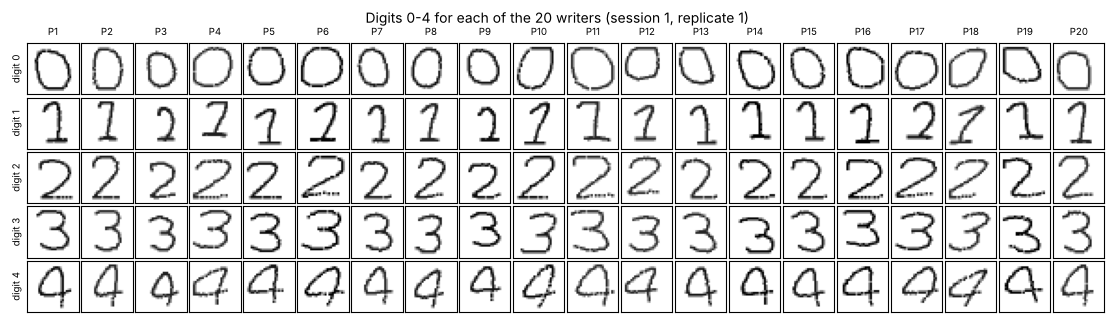

In [4]:
rows = [[find(p, d, 1, 1) for p in range(1, 21)] for d in range(5)]
fig = image_panel(rows, row_labels=[f"digit {d}" for d in range(5)],
                  col_labels=[f"P{p}" for p in range(1, 21)],
                  title="Digits 0-4 for each of the 20 writers (session 1, replicate 1)")
plt.show()

*(L. Nkejane)* The figure shows each digit as written by each of the 20 people, with session and
replicate held fixed. All digits are clearly recognisable, but writers differ visibly in size,
slant, aspect ratio and stroke thickness, which indicates that handwriting style is a substantial
source of variation. The digit 1 is drawn with a hooked top and a flat base, which makes it
resemble a 2 for several writers. This suggests that these two classes may be the most difficult
to distinguish.

> **Review note:** our task predicts the *writer*, not the digit, so 1-vs-2 confusion matters
> less here. What matters is that a writer's 1 has distinctive features (hook, base), which may
> help writer identification.

### Simple style measurements

Interpretable per-image measurements: total ink (stroke thickness and size), width and height of
the inked area, and slant (positive = leans right).

In [5]:
features.groupby("digit")[["ink", "width", "height", "slant"]].mean().round(2)

,ink,width,height,slant
digit,,,,
0,84.699997,19.12,21.13,-0.01
1,66.650002,13.48,20.69,-0.02
2,79.870003,18.50,21.30,0.11
3,77.690002,17.57,20.75,0.01
4,77.300003,17.52,19.62,0.11


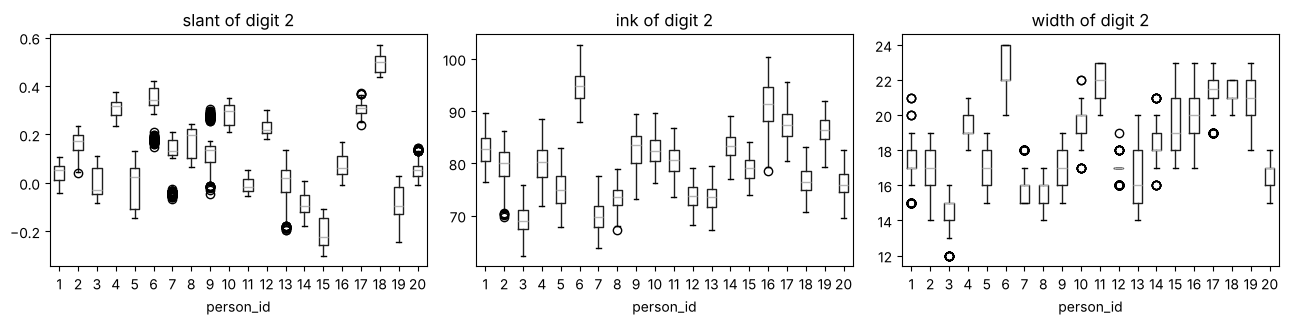

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
digit2 = features[features.digit == 2]
for ax, col in zip(axes, ["slant", "ink", "width"]):
    digit2.boxplot(column=col, by="person_id", ax=ax, grid=False)
    ax.set_title(f"{col} of digit 2")
    ax.set_xlabel("person_id")
plt.suptitle("")
plt.tight_layout()
plt.show()

## 3. Variation across sessions and replicates

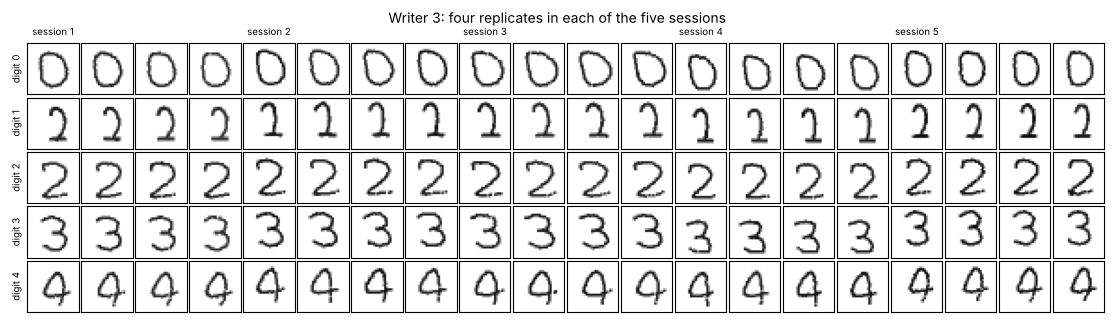

In [7]:
rows = [[find(3, d, s, r) for s in range(1, 6) for r in range(1, 5)] for d in range(5)]
col_labels = [f"session {s}" if r == 1 else "" for s in range(1, 6) for r in range(1, 5)]
fig = image_panel(rows, row_labels=[f"digit {d}" for d in range(5)], col_labels=col_labels,
                  title="Writer 3: four replicates in each of the five sessions")
plt.show()

*(L. Nkejane)* The figure shows one writer across all five sessions, with four replicates per
session. Replicates within a session are almost identical, whereas the same digit varies slightly
between sessions in position, size and stroke weight while keeping the same underlying shape.
The writer is therefore consistent across sessions, and the session effect is a small,
writer-specific perturbation. Within-session variation is much smaller than between-session or
between-person variation.

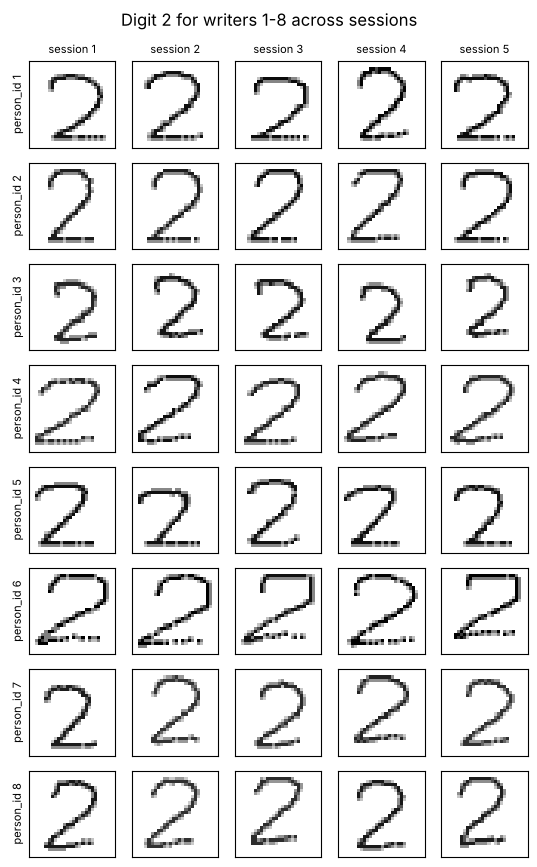

In [8]:
fig = show_grid(images, meta, row_var="person_id", col_var="session",
                row_values=range(1, 9), col_values=range(1, 6),
                fixed={"digit": 2}, title="Digit 2 for writers 1-8 across sessions")
plt.show()

Each line is one writer. Flat lines mean the writer is stable across sessions.

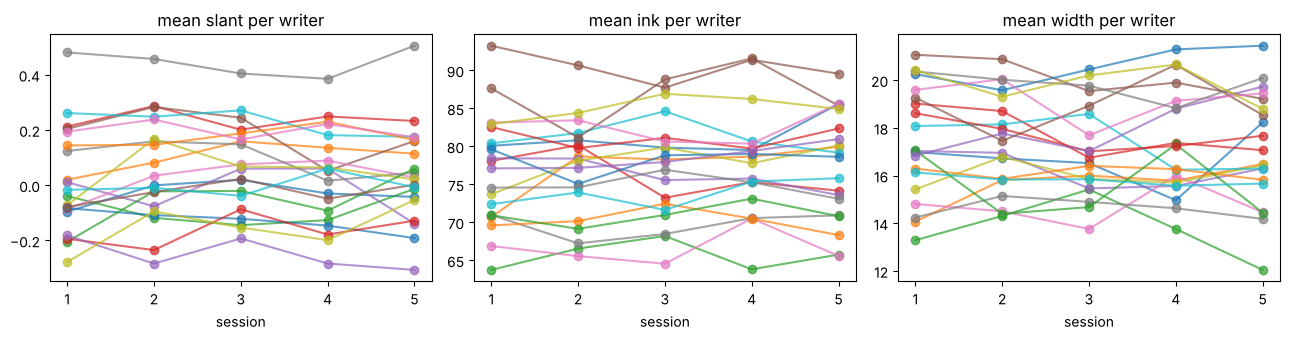

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ["slant", "ink", "width"]):
    table = features.pivot_table(index="session", columns="person_id", values=col)
    table.plot(ax=ax, legend=False, marker="o", alpha=0.7)
    ax.set_title(f"mean {col} per writer")
    ax.set_xticks(range(1, 6))
plt.tight_layout()
plt.show()

## 4. How much variation does each factor explain?

### Pixel variance (η²)

Between-group sum of squares divided by total sum of squares, over all 784 pixels.
The *person × digit* row is added to the original table: comparing it with
*person × digit × session* shows how much the session adds once writer and digit are known.

In [10]:
grand_mean = X.mean(axis=0)
total_ss = ((X - grand_mean) ** 2).sum()

def eta_squared(columns):
    group = meta.groupby(columns).ngroup().to_numpy()
    n = np.bincount(group)
    group_means = np.zeros((n.size, X.shape[1]))
    np.add.at(group_means, group, X)
    group_means /= n[:, None]
    return (n * ((group_means - grand_mean) ** 2).sum(axis=1)).sum() / total_ss

groupings = {"Digit": ["digit"],
             "Person": ["person_id"],
             "Session": ["session"],
             "Person x digit": ["person_id", "digit"],
             "Person x digit x session": ["person_id", "digit", "session"]}
eta = pd.DataFrame({"Groups": [meta.groupby(c).ngroups for c in groupings.values()],
                    "Share of pixel variance": [eta_squared(c) for c in groupings.values()]},
                   index=groupings.keys())
eta.round(3)

,Groups,Share of pixel variance
Digit,5,0.133
Person,20,0.111
Session,5,0.006
Person x digit,100,0.475
Person x digit x session,500,0.914


*(L. Nkejane)* The table reports the proportion of total pixel variance explained by each grouping
factor (η²), computed as the between-group sum of squares divided by the total sum of squares.
Digit explains 13.3% of the variance and person explains 11.1%, so the class label is only a
modest signal in raw pixel space and writer identity is of comparable importance. Session explains
0.6% on its own, because session effects are specific to each writer and cancel when averaged
across writers. Once the full person × digit × session cell is known, 91.4% of the variance is
explained, leaving under 10% as within-cell variation. This confirms that replicates within a cell
are close to duplicates. These values should not be ranked directly, because the groupings differ
greatly in the number of groups (5 digits against 500 cells), and a grouping with more groups will
explain more variance by construction.

### Style measurements

The same idea applied to the style measurements. *Within session* is the share left over between
the 50 replicates of one writer, digit and session.

In [11]:
rows = []
for col in ["ink", "width", "height", "slant", "x_centre", "y_centre"]:
    total = features[col].var()
    def explained(groups):
        return features.groupby(groups)[col].transform("mean").var() / total
    cell_mean = features.groupby(["person_id", "digit", "session"])[col].transform("mean")
    rows.append({
        "measurement": col,
        "digit": explained(["digit"]),
        "writer + digit": explained(["person_id", "digit"]),
        "writer + digit + session": explained(["person_id", "digit", "session"]),
        "within session (left over)": ((features[col] - cell_mean) ** 2).mean() / total,
    })
pd.DataFrame(rows).set_index("measurement").round(2)

,digit,writer + digit,writer + digit + session,within session (left over)
measurement,,,,
ink,0.40,0.90,0.95,0.05
width,0.42,0.88,0.97,0.03
height,0.16,0.71,0.87,0.13
slant,0.10,0.90,1.00,0.00
x_centre,0.32,0.80,1.00,0.00
y_centre,0.15,0.59,0.99,0.01


### Pixel distance between pairs of images (same digit)

Three kinds of pairs: two replicates from the same session, the same writer in different
sessions, and two different writers.

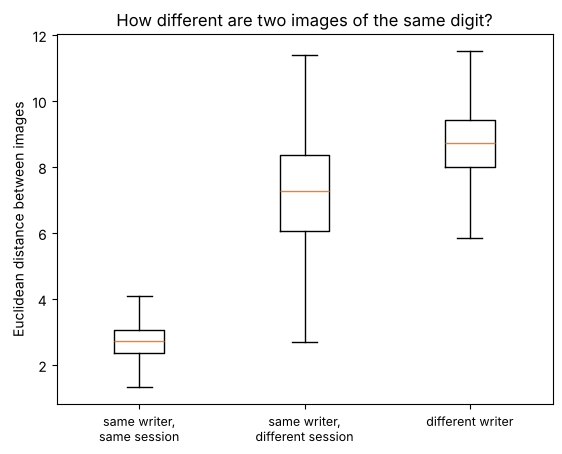

,"same writer, same session","same writer, different session",different writer
25%,2.37,6.07,7.99
50%,2.74,7.28,8.73
75%,3.06,8.36,9.43


In [12]:
person, digit, session = meta.person_id.values, meta.digit.values, meta.session.values
all_idx = np.arange(len(X))
rng = np.random.default_rng(1)

pair_types = {"same writer, same session": [],
              "same writer, different session": [],
              "different writer": []}
for _ in range(5000):
    i = rng.integers(len(X))
    same_digit = digit == digit[i]
    candidates = {
        "same writer, same session": same_digit & (person == person[i]) & (session == session[i]) & (all_idx != i),
        "same writer, different session": same_digit & (person == person[i]) & (session != session[i]),
        "different writer": same_digit & (person != person[i]),
    }
    for name, mask in candidates.items():
        j = rng.choice(all_idx[mask])
        pair_types[name].append(np.linalg.norm(X[i] - X[j]))

plt.boxplot(list(pair_types.values()), showfliers=False)
plt.xticks([1, 2, 3], [name.replace(", ", ",\n") for name in pair_types], fontsize=9)
plt.ylabel("Euclidean distance between images")
plt.title("How different are two images of the same digit?")
plt.show()

pd.DataFrame(pair_types).describe().loc[["25%", "50%", "75%"]].round(2)

> **Review note on the session effect.** Section 3's text calls the session effect *small*.
> It looks small by eye, but the numbers say it is large:
>
> - Pixel variance explained rises from **0.475** (person × digit) to **0.914** once session is
>   added, so session accounts for roughly 44% of the pixel variance within a writer and digit.
> - The same writer in a different session (median distance ≈ 7.3) is almost as far apart as two
>   different writers (≈ 8.7). Two replicates from one session are ≈ 2.7 apart.
> - In Task 2, writer-ID accuracy drops from about 0.999 with a random split to about 0.56–0.64
>   on an unseen session.
>
> A more accurate wording: the session effect keeps the writer's basic shape but shifts position,
> size, slant and stroke weight, and these shifts are large compared with the differences between
> writers. The claim that session explains only 0.6% *on its own* stays correct.

## 5. Principal components

variance explained by PC1 + PC2: 0.143


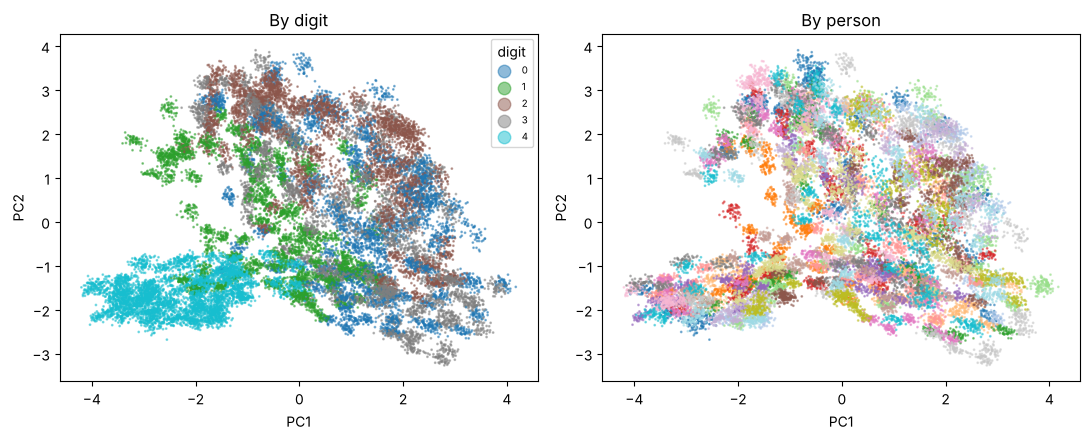

In [13]:
pca = PCA(n_components=2).fit(X)
Z = pca.transform(X)
print("variance explained by PC1 + PC2:", round(pca.explained_variance_ratio_.sum(), 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, col, cmap, title in [(axes[0], "digit", "tab10", "By digit"),
                             (axes[1], "person_id", "tab20", "By person")]:
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=meta[col], cmap=cmap, s=1, alpha=0.5)
    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
axes[0].legend(*axes[0].collections[0].legend_elements(), title="digit",
               fontsize=7, markerscale=1.5, loc="best")
plt.tight_layout()
plt.show()

*(L. Nkejane)* The images are projected onto the first two principal components, which together
explain only about 14% of the variance. When coloured by digit, the digit 4 forms a fairly
distinct region, while the remaining digits overlap heavily. When coloured by person, the same
cloud breaks into many small clusters. The data thus consist of many tight clusters, each
corresponding to one person × digit × session cell. Because the projection is linear and captures
little of the total variance, the overlap shown does not imply that the classes are inseparable.
The figure should be read as an illustration of this clustered structure, not as a measure of
class separability.

## 6. Summary: sources of variation and limitations

*(L. Nkejane)* The near-duplicate replicates mean that the effective sample size is far smaller
than 25,000, closer to the 500 distinct cells. Random train–test splits would therefore place
near-identical images in both sets and overestimate performance. Evaluation should instead hold
out whole people or whole sessions. The images are also clean, centred and free of noise, and the
session effects appear to be simple parametric shifts, which may not reflect real handwriting.
The dataset is limited to five digit classes and twenty writers, and findings may not generalise
beyond this setting.

**Additional points from notebooks 01 and 02** (to work into the report in your own words):

- **Sources of variation, largest to smallest within a digit:** writer, then session (shifts in
  slant, size, position and stroke weight), then replicate (tiny).
- **Stroke appearance:** strokes look like dotted, stamped pen paths, with no paper texture,
  scanning noise, or touching or broken digits.
- **Perfect balance:** 50 images in every cell, unlike real collections.
- **Unknown simulator:** the generator's settings are unknown, so a model may learn the
  simulator's rules rather than real handwriting traits.
- **Holding out writers** suits a matching task (Task 3, Siamese network). Writer
  *identification* (Task 2) must see every writer in training, so it holds out sessions instead.